# Fig. 1h-j: Model-derived values

[AI generated summary] Values of the foraging model (V_stay) and of the RL model (Q-values), computed with the parameters fitted to each monkey (`MODEL_PARAMS` and `MODEL_PARAMS_sRL` in `popy/config.py`):
- **Fig. 1h**: choices and model values in an example session (KA, session 210322; blocks 1 and 3 are shown in the paper).
- **Fig. 1i-j**: model values predict choices: probability of staying vs. V_stay and of choosing an action vs. its Q-value (i), and ROC curves (j).

**How to run:** set `DATA_PATH` in `popy/config.py`, then run all cells. Uses `behavior/behavior_kapo.pkl`. Figures are saved in `figs/`. Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, accuracy_score
from imblearn.under_sampling import RandomUnderSampler
from sklearn.preprocessing import label_binarize

from popy.io_tools import load_behavior
from popy.behavior_data_tools import add_foraging_value, add_RL_values, drop_time_fields, add_switch_info
from popy.plotting.plotting_tools import show_target_selection_compact
from popy.config import COLORS

from helpers import get_proportions

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

---
# Fig. 1h, Example blocks (animal's choices & model-derived values)

In [3]:
behav_all = load_behavior()  # load behavioral data
behav_all = drop_time_fields(behav_all)  # drop columns related to event timing
behav_all

,monkey,session,trial_id,block_id,best_target,target,feedback
0,ka,010720,0,0,2,3.0,1.0
1,ka,010720,1,0,2,3.0,0.0
2,ka,010720,2,0,2,1.0,1.0
3,ka,010720,3,0,2,1.0,0.0
4,ka,010720,4,0,2,3.0,1.0
...,...,...,...,...,...,...,...
39214,po,310822,419,9,2,1.0,0.0
39215,po,310822,420,9,2,1.0,1.0
39216,po,310822,421,9,2,1.0,1.0
39217,po,310822,422,9,2,1.0,1.0


In [4]:
# select data for one monkey and one session (displayed in the paper)
monkey, session = 'ka', '210322'
behav = behav_all[(behav_all['monkey'] == monkey) & (behav_all['session'] == session)].copy()
behav

,monkey,session,trial_id,block_id,best_target,target,feedback
16734,ka,210322,0,0,1,2.0,0.0
16735,ka,210322,1,0,1,3.0,0.0
16736,ka,210322,2,0,1,1.0,1.0
16737,ka,210322,3,0,1,1.0,0.0
16738,ka,210322,4,0,1,3.0,0.0
...,...,...,...,...,...,...,...
17154,ka,210322,420,9,3,3.0,1.0
17155,ka,210322,421,9,3,3.0,0.0
17156,ka,210322,422,9,3,3.0,0.0
17157,ka,210322,423,9,3,3.0,0.0


In [5]:
# add model-derived value estimates
behav = add_foraging_value(behav)  # add value function (it is an example to show how to plot some extra variables together with the behavior...)
behav = add_RL_values(behav)  # add value function (it is an example to show how to plot some extra variables together with the behavior...)
behav

,monkey,session,trial_id,block_id,best_target,target,feedback,stay_value,V0,Q_1,Q_2,Q_3
0,ka,210322,0,0,1,2.0,0.0,0.110103,0.110103,0.000000,0.000000,0.000000
1,ka,210322,1,0,1,3.0,0.0,0.061661,0.110103,0.255797,0.000000,0.255797
2,ka,210322,2,0,1,1.0,1.0,0.061661,0.110103,0.446161,0.255797,0.190365
3,ka,210322,3,0,1,1.0,0.0,0.501630,0.110103,0.587831,0.190365,0.141670
4,ka,210322,4,0,1,3.0,0.0,0.280929,0.110103,0.437466,0.397467,0.361228
...,...,...,...,...,...,...,...,...,...,...,...,...
420,ka,210322,420,9,3,3.0,1.0,0.827354,0.110103,0.259870,0.259868,0.740135
421,ka,210322,421,9,3,3.0,0.0,0.903313,0.110103,0.193396,0.193395,0.806607
422,ka,210322,422,9,3,3.0,0.0,0.505883,0.110103,0.399723,0.399722,0.600280
423,ka,210322,423,9,3,3.0,0.0,0.283310,0.110103,0.553272,0.553271,0.446730


In the paper, we show **block id: 1** and **block id: 3** as examples.

Blocks are continuous, dashed vertical line marks the last five trials (i.e., payoff probabilities switch gradually).

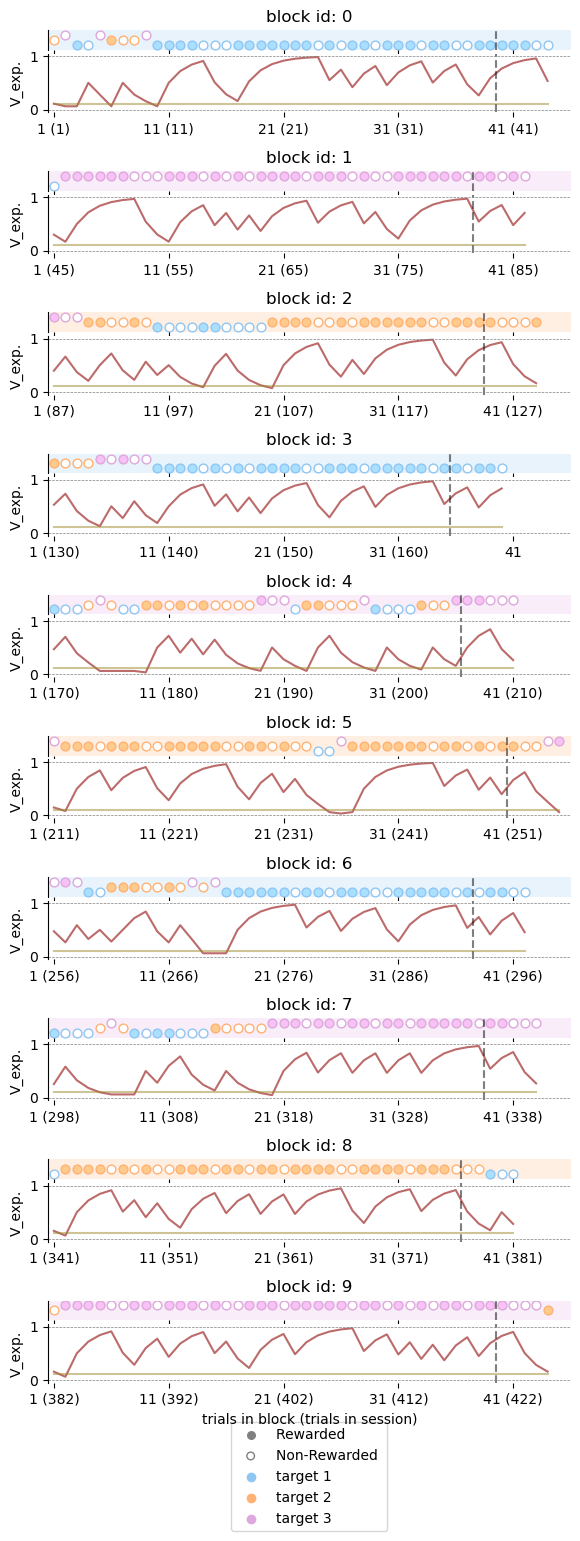

In [6]:
# Foraging value-based target selection plot
show_target_selection_compact(behav, 
                              format='False',
                              background_values=['stay_value', 'V0'],   # here we tell what variable to use as background - value in this case
                              ylabel='V_exp.',
                              savedir=os.path.join(FIGS_PATH, 'fig1h_foraging_values.svg'))

In [7]:
# Export source data (Figure 1h)
from popy.source_data import export_source_data
from popy.behavior_data_tools import add_trial_in_block

# the two example blocks shown in the paper, as plotted above: example block 1 = block id 3, example block 2 = block id 1
example_blocks_1h = {3: 1, 1: 2}  # block id: example block in the paper
behav_1h = add_trial_in_block(behav.copy())
behav_1h = pd.concat([behav_1h[behav_1h['block_id'] == b] for b in example_blocks_1h])
df_1h = pd.DataFrame({
    'Example block (paper)': behav_1h['block_id'].map(example_blocks_1h),
    'Block id': behav_1h['block_id'],
    'Trial in block': behav_1h['trial_id_in_block'] + 1,
    'Trial in session': behav_1h['trial_id'] + 1,
    'High-payoff target (background)': behav_1h['best_target'],
    'Chosen target (row of the circle)': behav_1h['target'],
    'Rewarded (1: filled, 0: empty circle; empty: interrupted trial)': behav_1h['feedback'],
    'V_stay (foraging model, red line)': behav_1h['stay_value'],
    'Switching threshold tau (V0, light brown line)': behav_1h['V0'],
})
title_1h = f'Monkey {monkey.upper()}, session {session}'
desc_1h = (f'Choices of monkey {monkey.upper()} in two example blocks of session {session} (example block 1 and 2 = block id 3 and 1 of the '
           'session), one row per trial (x: trial in block, 1 = first trial; the paper panel shows the first 26 trials of each block, all trials '
           'are given here): chosen target (1-3), outcome (filled circle: rewarded, empty circle: unrewarded) and high-payoff target of the '
           'block (background color), with the model values of the trial (before its feedback). '
           'Top: foraging model value V_stay (red) and switching threshold tau (light brown).')
export_source_data('Figure 1h', {title_1h: df_1h}, desc_1h)

Figure 1h: source data saved (82 rows)


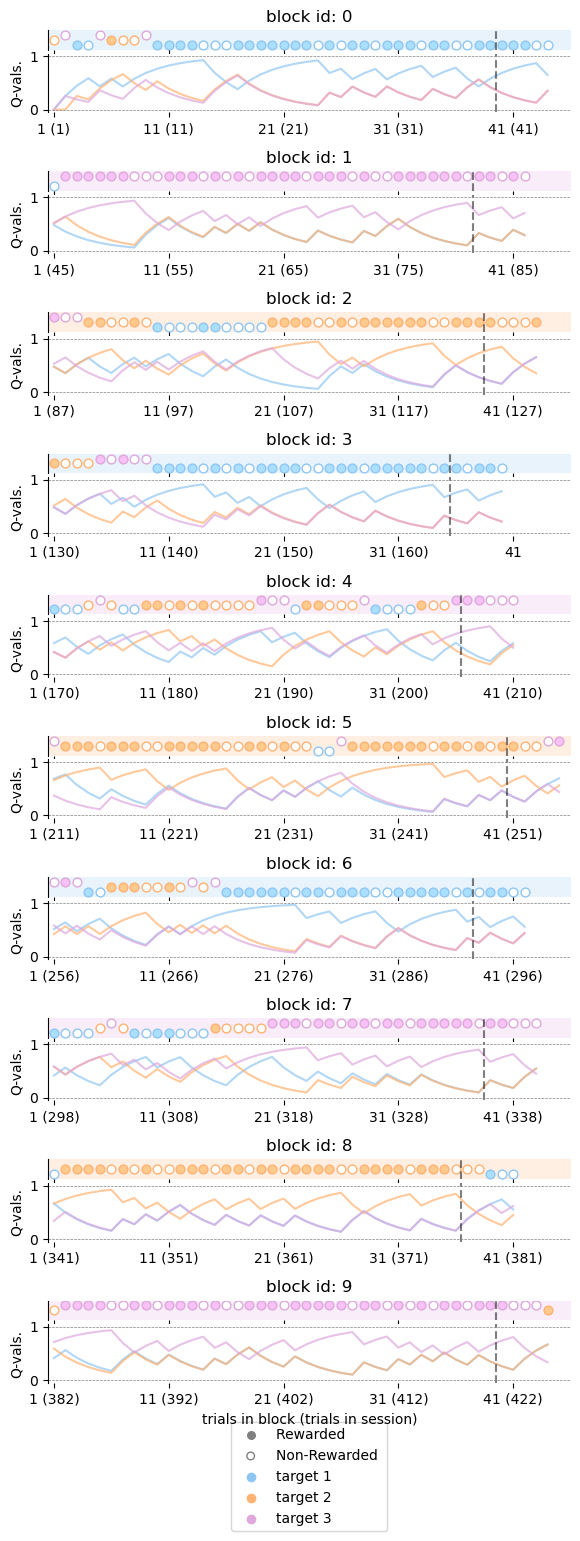

In [8]:
# RL value-based target selection plot
show_target_selection_compact(behav, 
                              format='False',
                              background_values=['Q_1', 'Q_2', 'Q_3'],   # here we tell what variable to use as background - value in this case
                              ylabel='Q-vals.',
                              savedir=os.path.join(FIGS_PATH, 'fig1h_q_values.svg'))

In [9]:
# Export source data (Figure 1h)
from popy.source_data import export_source_data

for k in [1, 2, 3]:
    df_1h[f'Q_{k} (RL model, value of target {k})'] = behav_1h[f'Q_{k}'].values
export_source_data('Figure 1h', {title_1h: df_1h}, desc_1h + ' Bottom: RL model Q-values of the three targets (Q_1-Q_3, colors of the targets).')

Figure 1h: source data saved (82 rows)


---
# Fig. 1i-j, Model-derived values predict animal's choices

In [10]:
# Update the default font size
plt.rcParams.update({'font.size': 8})

# load the behavior data and add the model-derived values
behav = load_behavior()
behav = drop_time_fields(behav)
behav = behav.dropna(subset=['target'])

behav = add_foraging_value(behav, add_PE=True)
behav = add_RL_values(behav, add_PE=True)
behav = add_switch_info(behav, add_trials_since_switch=False)

behav

,monkey,session,trial_id,block_id,best_target,target,feedback,stay_value,V0,PE_foraging,Q_1,Q_2,Q_3,PE_RL,switch
0,ka,010720,0,0,2,3.0,1.0,0.110103,0.188963,0.889897,0.000000,0.000000,0.000000,1.000000,NaN
1,ka,010720,1,0,2,3.0,0.0,0.501630,0.188963,-0.501630,0.000000,0.000000,0.255797,-0.255797,0.0
2,ka,010720,2,0,2,1.0,1.0,0.280929,0.188963,0.889897,0.255797,0.255797,0.190365,0.744203,1.0
3,ka,010720,3,0,2,1.0,0.0,0.501630,0.188963,-0.501630,0.446161,0.190365,0.141670,-0.446161,0.0
4,ka,010720,4,0,2,3.0,1.0,0.280929,0.188963,0.889897,0.332035,0.397467,0.361228,0.638772,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39170,po,310822,419,9,2,1.0,0.0,0.595735,0.188963,-0.595735,0.767624,0.436690,0.232394,-0.767624,0.0
39171,po,310822,420,9,2,1.0,1.0,0.420597,0.188963,0.579403,0.509311,0.626249,0.490701,0.490689,0.0
39172,po,310822,421,9,2,1.0,1.0,0.590934,0.188963,0.409066,0.674433,0.415510,0.325575,0.325567,0.0
39173,po,310822,422,9,2,1.0,1.0,0.711194,0.188963,0.288806,0.783989,0.275687,0.216016,0.216011,0.0


In [11]:
##% plotting functions
def plot_probab_of_stay(probab_of_stay_full, bin_centers, ax=None, monkey=None, lw=1, show_data=False, xlabel='Stay value', ylabel='Probability of stay'):
    """
    Plot the probability of switch as a function of the value function.
    """
    if ax is None:
        cm = 1/2.54  # centimeters in inches
        fig, ax = plt.subplots()
        fig.set_size_inches(4*cm, 3*cm)

    # first plot : probab of switch
    # plot mean
    linestyle = 'dashed' if monkey.split('_')[-1] == 'simulation' else 'solid'
    if linestyle == 'dashed':
        color = COLORS['_'.join(monkey.split('_')[:-1])]
    else:
        color = COLORS[monkey]
    alpha = .5 if monkey.split('_')[-1] == 'simulation' else 1

    # Calculate mean and error
    means = np.nanmean(probab_of_stay_full, axis=0)
    sems = np.nanstd(probab_of_stay_full, axis=0) / np.sqrt(probab_of_stay_full.shape[0])  # Standard Error of the Mean 
    
    # Plot line
    ax.plot(bin_centers,
            means,
            linewidth=lw,
            color=color,
            linestyle=linestyle,
            label=monkey.upper() if monkey is not None else 'Mean')

    # Add shaded error region
    ax.fill_between(bin_centers,
                    means - sems,
                    means + sems,
                    color=color,
                    alpha=0.2)  # Transparency level
    
    ax.axhline(0.5, color='grey', linestyle='dashed', linewidth=1)
    # plot std
    '''ax.fill_between(x_bins[:-1], 
                    np.mean(probab_of_switch_full, axis=0) - np.std(probab_of_switch_full, axis=0), 
                    np.mean(probab_of_switch_full, axis=0) + np.std(probab_of_switch_full, axis=0), 
                    color=COLORS[monkey], alpha=0.2)'''

    # plot settings
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    ax.set_ylim([-0.05, 1.05])
    ax.set_xlim(bin_centers.min()-0.05, bin_centers.max()+0.05)

    # hide the right and top spines
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

    #ax.grid(alpha=0.3)
    ax.legend(frameon=False, loc='lower right', fontsize=6)

    return ax

def plot_roc_curve(fpr, tpr, auc, ax=None, monkey=None, lw=5):
    """
    Plot the ROC curve and the AUC.
    """
    if ax is None:
        cm = 1/2.54  # centimeters in inches
        fig, ax = plt.subplots()
        fig.set_size_inches(5*cm, 5*cm)
        # Set equal aspect ratio for the plot
        ax.set_aspect('equal', adjustable='box')

    # plot unbalance
    linestyle = 'dashed' if monkey.split('_')[-1] == 'simulation' else 'solid'
    if linestyle == 'dashed':
        color = COLORS['_'.join(monkey.split('_')[:-1])]
    else:
        color = COLORS[monkey]

    ax.plot(fpr, tpr, 
            label=f'{monkey.upper()}, AuC {auc:.2f}' if monkey is not None else 'ROC curve', 
            linewidth=lw, color=color, linestyle=linestyle)
    # fill under the curve
    ax.fill_between(fpr, tpr, color='grey', alpha=.1)

    # plot chance
    ax.plot([0, 1], [0, 1], color='grey', linestyle='dashed')

    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')

    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.legend(frameon=False, loc='lower right', fontsize=6)

    # Adjust layout
    if ax.get_figure() is not None:
        ax.get_figure().tight_layout()

    return ax

def plot_value_vs_shift(behav, paper_format=False):
    # Main plotting loop
    if paper_format:
        plt.rcParams.update({'font.size': 8})
        lw_1, lw_2 = 1.5, 2.3

        mm = 1 / 25.4          # mm to inches
        ax_size = 24.5 * mm    # 24.5 mm axes size (excluding labels/ticks)

        # Margins in inches to accommodate labels and ticks
        left_m, right_m, bottom_m, top_m, h_gap = 0.50, 0.10, 0.45, 0.15, 0.40
        fig_w = left_m + ax_size + h_gap + ax_size + right_m
        fig_h = bottom_m + ax_size + top_m

        fig = plt.figure(figsize=(fig_w, fig_h))
        axs = [
            fig.add_axes([left_m / fig_w, bottom_m / fig_h, ax_size / fig_w, ax_size / fig_h]),
            fig.add_axes([(left_m + ax_size + h_gap) / fig_w, bottom_m / fig_h, ax_size / fig_w, ax_size / fig_h]),
        ]
    else:
        plt.rcParams.update({'font.size': 18})
        h, w1, w2 = 4, 6, 4
        lw_1, lw_2 = 5, 3  # line width

        # Calculate total width and width ratios to achieve desired subplot sizes
        total_width = w1 + w2
        width_ratios = [w1, w2]  # Use actual widths as ratios
        
        fig, axs = plt.subplots(1, 2, figsize=(total_width, h), 
                               gridspec_kw={'width_ratios': width_ratios, 'wspace': 0})
        
        # Ensure the second subplot is square by adjusting its aspect ratio
        axs[1].set_aspect('equal', adjustable='box')

    ### 1. Probability of switch vs value function

    # get 95% of the data range
    x_min, x_max = np.percentile(behav['stay_value'], [2.5, 97.5]).min(), np.percentile(behav['stay_value'], [2.5, 97.5]).max()
    x_bins = np.linspace(x_min, x_max, 11)
    bin_centers = (x_bins[:-1] + x_bins[1:]) / 2

    for monkey, behav_monkey in behav.groupby('monkey'):
        probas_per_monkey = []

        for session, behav_temp in behav_monkey.groupby('session'):
            behav_temp = behav_temp.dropna()  # drop NaN values

            # get data for probability of switch plot
            stay_values = behav_temp['stay_value'].values
            y_true = behav_temp['switch'].values
            y_true = y_true.astype(int)  # convert y to 0 and 1
            y_true = 1 - y_true  # switch = 1, stay = 0

            # balance classes by undersampling majority class
            stay_values, y_true = RandomUnderSampler().fit_resample(stay_values.reshape(-1, 1), y_true)
            stay_values = stay_values.flatten()

            # get proportions
            proportions = get_proportions(stay_values, y_true, x_bins)

            # ROC AUC
            fpr, tpr, _ = roc_curve(y_true, stay_values, drop_intermediate=False, pos_label=0)
            auc = roc_auc_score(-y_true, stay_values)

            # accuracy
            accuracy = accuracy_score(y_true, (stay_values >= 0.5).astype(int))

            probas_per_monkey.append(proportions)

        probas_per_monkey = np.array(probas_per_monkey)

        # plot probability of stay
        plot_probab_of_stay(probas_per_monkey, bin_centers, ax=axs[0], monkey=monkey, lw=lw_1, show_data=False)

    ### 2. ROC curve and AUC for binary switch/stay
    
    for monkey, behav_monkey in behav.groupby('monkey'):
        behav_monkey = behav_monkey.dropna()  # drop NaN values

         # get data for probability of switch plot
        stay_values = behav_monkey['stay_value'].values
        y_true = behav_monkey['switch'].values
        y_true = y_true.astype(int)  # convert y to 0 and 1
        #y_true = 1 - y_true  # switch = 1, stay =

        # balance classes by undersampling majority class
        #stay_values, y_true = RandomUnderSampler().fit_resample(stay_values, y_true)
        #stay_values = stay_values.flatten()

        # ROC AUC
        fpr, tpr, _ = roc_curve(y_true, stay_values, drop_intermediate=False, pos_label=0)
        auc = roc_auc_score(-y_true, stay_values)

        # accuracy
        print(f"{monkey} ROC AUC (binary switch/stay): {auc:.3f}")

        plot_roc_curve(fpr, tpr, auc, ax=axs[1], monkey=monkey, lw=lw_2)
        
    # Save the figures
    if not paper_format:
        fig.tight_layout()

    return fig, axs

def plot_q_vals_vs_decision(behav, paper_format=False):
    # Main plotting loop
    if paper_format:
        plt.rcParams.update({'font.size': 8})
        lw_1, lw_2 = 1.5, 2.3

        mm = 1 / 25.4          # mm to inches
        ax_size = 24.5 * mm    # 24.5 mm axes size (excluding labels/ticks)

        # Margins in inches to accommodate labels and ticks
        left_m, right_m, bottom_m, top_m, h_gap = 0.50, 0.10, 0.45, 0.15, 0.40
        fig_w = left_m + ax_size + h_gap + ax_size + right_m
        fig_h = bottom_m + ax_size + top_m

        fig = plt.figure(figsize=(fig_w, fig_h))
        axs = [
            fig.add_axes([left_m / fig_w, bottom_m / fig_h, ax_size / fig_w, ax_size / fig_h]),
            fig.add_axes([(left_m + ax_size + h_gap) / fig_w, bottom_m / fig_h, ax_size / fig_w, ax_size / fig_h]),
        ]
    else:
        plt.rcParams.update({'font.size': 18})
        h, w1, w2 = 4, 6, 4
        lw_1, lw_2 = 5, 3  # line width

        # Calculate total width and width ratios to achieve desired subplot sizes
        total_width = w1 + w2
        width_ratios = [w1, w2]  # Use actual widths as ratios
        
        fig, axs = plt.subplots(1, 2, figsize=(total_width, h), 
                               gridspec_kw={'width_ratios': width_ratios, 'wspace': 0})
        
        # Ensure the second subplot is square by adjusting its aspect ratio
        axs[1].set_aspect('equal', adjustable='box')

    ### 1. Probability of switch vs value function

    # get 95% of the data range
    x_min, x_max = np.percentile(behav[['Q_1', 'Q_2', 'Q_3']].values.flatten(), [2.5, 97.5]).min(), np.percentile(behav[['Q_1', 'Q_2', 'Q_3']].values.flatten(), [2.5, 97.5]).max()
    x_bins = np.linspace(x_min, x_max, 11)
    bin_centers = (x_bins[:-1] + x_bins[1:]) / 2

    for monkey, behav_monkey in behav.groupby('monkey'):
        probas_per_monkey = []
        for session, behav_temp in behav_monkey.groupby('session'):
            behav_temp = behav_temp.dropna()  # drop NaN values

            # get data for probability of switch plot
            y_true = behav_temp['target']

            q_values = behav_temp[['Q_1', 'Q_2', 'Q_3']].values  # shape: (n_samples, 3)

            # balance classes by undersampling majority class
            #q_values, y_true = RandomUnderSampler().fit_resample(q_values, y_true)

            # For each sample, get the Q-value of the chosen/target option and whether it was correct
            q_chosen = []
            correct = []
            
            for j, target in enumerate(y_true):
                # Ensure target is integer and within valid range
                target_int = int(target)
                if target_int < 1 or target_int > 3:
                    continue  # Skip invalid targets
                    
                q_target = q_values[j, target_int-1]  # Get Q-value for the target (convert to 0-indexed)
                q_chosen.append(q_target)
                
                # Check if the highest Q-value corresponds to the target
                predicted = np.argmax(q_values[j]) + 1  # Convert back to 1-indexed
                correct.append(1 if predicted == target_int else 0)
            
            q_chosen = np.array(q_chosen)
            correct = np.array(correct)

            # get proportions
            proportions = get_proportions(q_chosen, correct, x_bins)
            
            probas_per_monkey.append(proportions)

        probas_per_monkey = np.array(probas_per_monkey)

        # plot probability of stay
        plot_probab_of_stay(probas_per_monkey, bin_centers, ax=axs[0], monkey=monkey, lw=lw_1, show_data=False, xlabel='Q value of chosen option', ylabel='Probability of\n'+r'action = argmax(Q_1, Q_2, Q_3)$')

    ### 2. ROC curve and AUC for binary switch/stay


    for monkey, behav_monkey in behav.groupby('monkey'):
        behav_monkey = behav_monkey.dropna()  # drop NaN values

        # get data for probability of switch plot
        y_true = behav_monkey['target']
        y_true_onehot = label_binarize(y_true, classes=[1, 2, 3])  # shape: (n_samples, 3)

        q_values = behav_monkey[['Q_1', 'Q_2', 'Q_3']].values  # shape: (n_samples, 3)

        fpr, tpr, _ = roc_curve(y_true_onehot.ravel(), q_values.ravel())
        auc_model2 = roc_auc_score(y_true_onehot, q_values, average='macro', multi_class='ovr')
        
        # accuracy score
        accuracy_model2 = np.mean(np.argmax(q_values, axis=1) + 1 == y_true)
        print(f"Model 2 Macro-Averaged AUC (3-way choice): {auc_model2:.3f}")
        print(f"Model 2 Accuracy (3-way choice): {accuracy_model2:.3f}")

        plot_roc_curve(fpr, tpr, auc_model2, ax=axs[1], monkey=monkey, lw=lw_2)

    # Save the figures
    if not paper_format:
        fig.tight_layout()

    return fig, axs

## Foraging model: stay value vs. stay/switch decision

ka ROC AUC (binary switch/stay): 0.941
po ROC AUC (binary switch/stay): 0.867


/var/folders/y6/tr60_9y13514h8wvk15tr4gc0000gn/T/ipykernel_93412/1598046964.py:97: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  ax.get_figure().tight_layout()
/var/folders/y6/tr60_9y13514h8wvk15tr4gc0000gn/T/ipykernel_93412/1598046964.py:97: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  ax.get_figure().tight_layout()


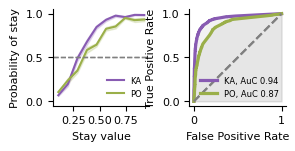

In [12]:
monkeys = ['ka', 'po']#, 'ka_simulation', 'po_simulation']

# Now when the warning occurs, it will raise an exception and stop execution
fig, axs = plot_value_vs_shift(behav.loc[behav['monkey'].isin(monkeys)], paper_format=True)

# save the figure svg
plt.savefig(os.path.join(FIGS_PATH, 'fig1ij_foraging_value.svg'), dpi=300, bbox_inches='tight', transparent=True, format='svg')

In [13]:
# Export source data (Figure 1i and Figure 1j, left: foraging model)
from popy.source_data import export_source_data


def curves_as_drawn(ax, x_name):
    """Mean ± SEM curves drawn by plot_probab_of_stay(), read from the axis: one line per monkey (labelled KA, PO) and its
    shading (fill_between of mean - SEM and mean + SEM, drawn in the same order). Read from the figure, because the per-session
    values of the foraging curve depend on a random undersampling."""
    lines = [line for line in ax.lines if line.get_label() in ('KA', 'PO')]
    df = pd.DataFrame({x_name: lines[0].get_xdata()})
    for line, band in zip(lines, ax.collections):
        vertices = np.concatenate([path.vertices for path in band.get_paths()])
        bounds = [vertices[np.isclose(vertices[:, 0], x), 1] for x in df[x_name]]
        df[f'{line.get_label()} mean'] = line.get_ydata()
        df[f'{line.get_label()} SEM'] = [(b.max() - b.min()) / 2 if len(b) else np.nan for b in bounds]
    return df


def roc_curves_as_drawn(ax):
    """ROC curves drawn by plot_roc_curve(), read from the axis (lines labelled 'KA, AuC ...', 'PO, AuC ...')"""
    return {line.get_label().split(',')[0]: pd.DataFrame({'False positive rate': line.get_xdata(), 'True positive rate': line.get_ydata()})
            for line in ax.lines if line.get_label().split(',')[0] in ('KA', 'PO')}


# number of sessions and AUCs (same data and computation as in plot_value_vs_shift)
behav_sd = behav.loc[behav['monkey'].isin(monkeys)]
n_sessions = '; '.join(f'{m.upper()}: n = {n} sessions' for m, n in behav_sd.groupby('monkey')['session'].nunique().items())
auc_1j_left = pd.DataFrame([
    {'Panel': 'left (foraging model, V_stay)', 'Monkey': m.upper(), 'n trials': len(b.dropna()),
     'ROC-AUC': roc_auc_score(-b.dropna()['switch'].values.astype(int), b.dropna()['stay_value'].values)}
    for m, b in behav_sd.groupby('monkey')])

sd_1i = {'Left: foraging model, P(stay) vs. V_stay': curves_as_drawn(axs[0], 'V_stay (bin center)')}
sd_1j = {'ROC-AUC (legend)': auc_1j_left} | {f'Left: foraging model (V_stay), ROC curve, monkey {m}': df for m, df in roc_curves_as_drawn(axs[1]).items()}

desc_1i = ('Model-derived values predict choices. x: centers of 10 equal-width bins spanning the 2.5th-97.5th percentiles of the value '
           '(both monkeys pooled). Left: probability of staying (vs. switching) as a function of the foraging model value V_stay; in each '
           'session, stay and switch trials were balanced by random undersampling of the majority class before computing the fraction of '
           f'stay trials per bin. Lines: mean across sessions; shading: mean ± SEM across sessions (SD / sqrt(n sessions); {n_sessions}). '
           'Dashed line (0.5): chance.')
desc_1j = ('ROC curves of predicting the choices from the model values, all trials of a monkey pooled across sessions (ROC-AUC table: area under '
           'the curve, as in the legend, and number of trials). Left: V_stay predicting stay vs. switch (positive class: stay). '
           'Diagonal dashed line: chance.')
export_source_data('Figure 1i', sd_1i, desc_1i)
export_source_data('Figure 1j', sd_1j, desc_1j)

Figure 1i: source data saved (10 rows)
Figure 1j: source data saved (2 rows, 13005 rows, 5606 rows)


## RL model: Q-values vs. action selection

Model 2 Macro-Averaged AUC (3-way choice): 0.874
Model 2 Accuracy (3-way choice): 0.770
Model 2 Macro-Averaged AUC (3-way choice): 0.774
Model 2 Accuracy (3-way choice): 0.643


/var/folders/y6/tr60_9y13514h8wvk15tr4gc0000gn/T/ipykernel_93412/1598046964.py:97: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  ax.get_figure().tight_layout()
/var/folders/y6/tr60_9y13514h8wvk15tr4gc0000gn/T/ipykernel_93412/1598046964.py:97: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  ax.get_figure().tight_layout()


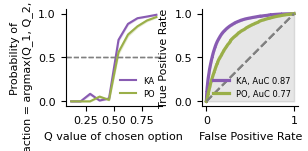

In [14]:
monkeys = ['ka', 'po']#, 'ka_simulation', 'po_simulation']

# Now when the warning occurs, it will raise an exception and stop execution
fig, ax = plot_q_vals_vs_decision(behav.loc[behav['monkey'].isin(monkeys)], paper_format=True)

# save the figure svg
plt.savefig(os.path.join(FIGS_PATH, 'fig1ij_q_values.svg'), dpi=300, bbox_inches='tight', transparent=True, format='svg')

In [15]:
# Export source data (Figure 1i and Figure 1j, right: RL model)
from popy.source_data import export_source_data

# AUCs (same data and computation as in plot_q_vals_vs_decision)
auc_1j_right = pd.DataFrame([
    {'Panel': 'right (RL model, Q-values)', 'Monkey': m.upper(), 'n trials': len(b.dropna()),
     'ROC-AUC': roc_auc_score(label_binarize(b.dropna()['target'], classes=[1, 2, 3]), b.dropna()[['Q_1', 'Q_2', 'Q_3']].values, average='macro', multi_class='ovr')}
    for m, b in behav_sd.groupby('monkey')])

sd_1i['Right: RL model, P(chosen action = argmax Q) vs. Q-value of the chosen action'] = curves_as_drawn(ax[0], 'Q-value of the chosen action (bin center)')
sd_1j['ROC-AUC (legend)'] = pd.concat([auc_1j_left, auc_1j_right], ignore_index=True)
sd_1j.update({f'Right: RL model (Q-values), ROC curve, monkey {m}': df for m, df in roc_curves_as_drawn(ax[1]).items()})

export_source_data('Figure 1i', sd_1i,
                   desc_1i + ' Right: probability that the chosen action was the one with the highest Q-value (RL model) as a function of the '
                   'Q-value of the chosen action, computed per session (all trials), then averaged across sessions (mean ± SEM, same sessions).')
export_source_data('Figure 1j', sd_1j,
                   desc_1j + ' Right: Q-values predicting the chosen target; the ROC curve pools the one-vs-rest problems of the three targets '
                   '(micro-average) and the ROC-AUC is the macro-average of the three one-vs-rest AUCs.')

Figure 1i: source data saved (10 rows, 10 rows)
Figure 1j: source data saved (4 rows, 13005 rows, 5606 rows, 18821 rows, 16214 rows)
